
# Sarcasm Detection


**Dataset:** Sarcasm Headlines Dataset

**Input:** Headline

**Target:** is_sarcastic


In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

In [2]:
file_path = "/content/Sarcasm_Headlines_Dataset_v2.json"
df = pd.read_json(file_path, lines=True)

#EDA

In [3]:
df.head()

,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...


In [5]:
df.shape

(28619, 3)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28619 entries, 0 to 28618
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   is_sarcastic  28619 non-null  int64 
 1   headline      28619 non-null  object
 2   article_link  28619 non-null  object
dtypes: int64(1), object(2)
memory usage: 670.9+ KB


In [7]:
df.isnull().sum()

,0
is_sarcastic,0
headline,0
article_link,0


In [8]:
df.columns.tolist()

['is_sarcastic', 'headline', 'article_link']

##Data Quality & Class Distribution

In [11]:
duplicate_count = df.duplicated(subset="headline").sum()

print("duplicate headlines:", duplicate_count)

duplicate headlines: 116


In [12]:
label_counts = df.groupby("headline")["is_sarcastic"].nunique()

conflicting_headlines = label_counts[label_counts > 1]

print("Headlines with conflicting labels:", len(conflicting_headlines))

Headlines with conflicting labels: 0


In [13]:
class_counts = df["is_sarcastic"].value_counts().sort_index()

print("\nClass Counts:")
print(class_counts)


Class Counts:
is_sarcastic
0    14985
1    13634
Name: count, dtype: int64


In [14]:
class_percentages = df["is_sarcastic"].value_counts(
    normalize=True
).sort_index() * 100

print("\nClass Percentages:")
print(class_percentages.round(2))


Class Percentages:
is_sarcastic
0    52.36
1    47.64
Name: proportion, dtype: float64


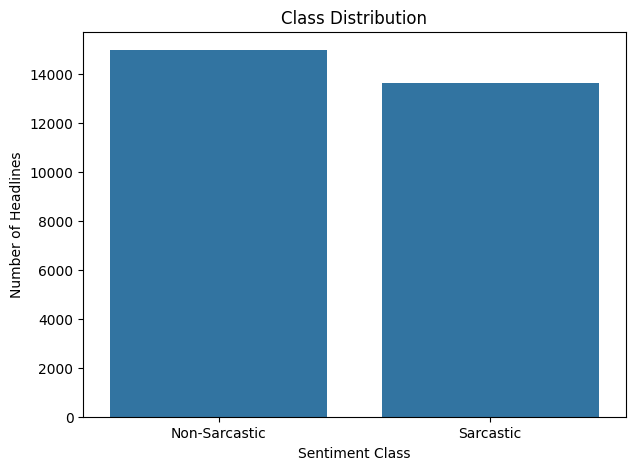

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="is_sarcastic")

plt.title("Class Distribution")
plt.xlabel("Sentiment Class")
plt.ylabel("Number of Headlines")
plt.xticks([0, 1], ["Non-Sarcastic", "Sarcastic"])

plt.show()

In [19]:
duplicate_rows = df[df.duplicated(subset="headline", keep=False)]

print("Total rows involved in duplicates:",
      len(duplicate_rows))

print("\nDuplicate examples:")
display(
    duplicate_rows.sort_values("headline").head(10)
)

df = df.drop_duplicates(
    subset="headline",
    keep="first"
).reset_index(drop=True)

print("\nShape after removing duplicates:")
print(df.shape)


Total rows involved in duplicates: 196

Duplicate examples:


,is_sarcastic,headline,article_link,word_count
7260,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
12216,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
12856,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
10254,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
10139,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
18118,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
15499,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
7184,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
5806,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12
5060,1,"'no way to prevent this,' says only nation whe...",https://www.theonion.com/no-way-to-prevent-thi...,12



Shape after removing duplicates:
(28503, 4)


In [20]:
df["word_count"] = df["headline"].apply(
    lambda text: len(str(text).split())
)

print("Headline Length Statistics:")
print(df["word_count"].describe())

Headline Length Statistics:
count    28503.000000
mean        10.060871
std          3.385275
min          2.000000
25%          8.000000
50%         10.000000
75%         12.000000
max        151.000000
Name: word_count, dtype: float64


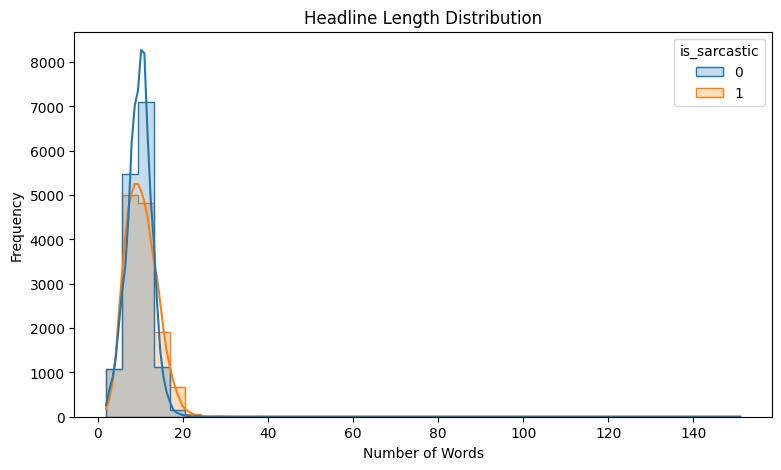

In [21]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="is_sarcastic",
    bins=40,
    kde=True,
    element="step"
)

plt.title("Headline Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [22]:
print(df.groupby("is_sarcastic")["word_count"].mean())


is_sarcastic
0     9.824360
1    10.321798
Name: word_count, dtype: float64


In [23]:
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [25]:
stop_words = set(stopwords.words('english'))
def get_word_frequency(texts, stop_words):
    words = []

    for text in texts:
        tokens = str(text).lower().split()

        for word in tokens:
            word = word.strip(".,!?;:'\"()[]{}")

            if word and word not in stop_words:
                words.append(word)

    return Counter(words)

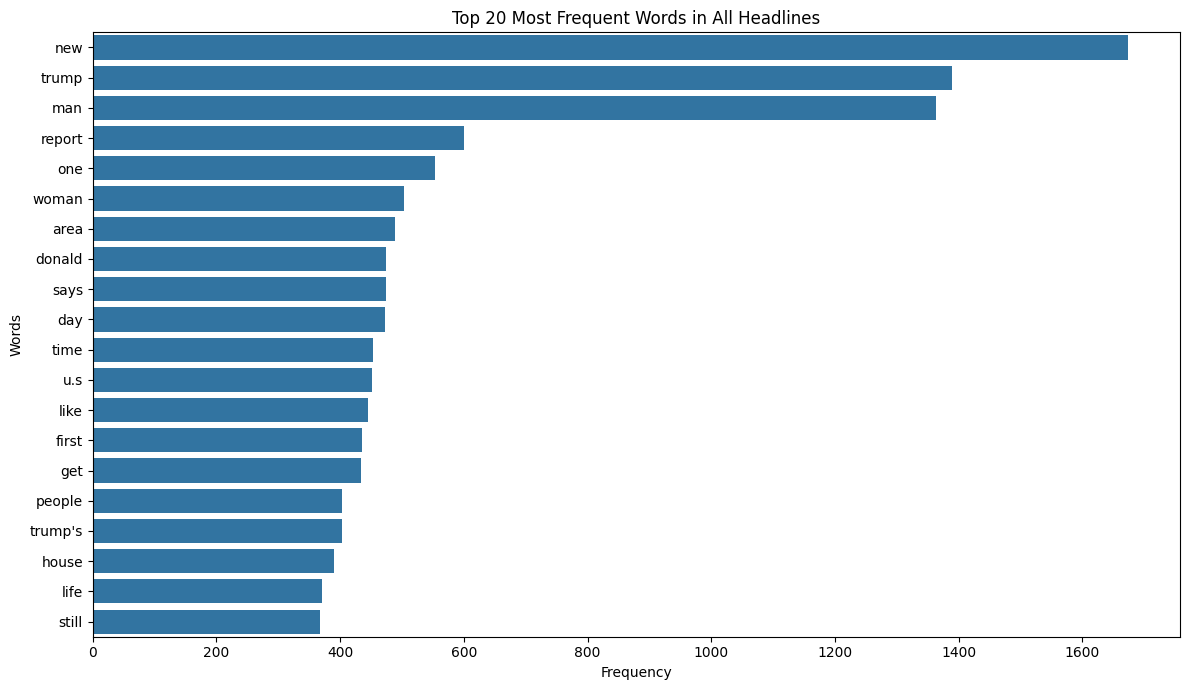

In [26]:
all_words = get_word_frequency(df['headline'], stop_words)

top_20_words = all_words.most_common(20)

words, counts = zip(*top_20_words)

plt.figure(figsize=(12, 7))
sns.barplot(x=list(counts), y=list(words))

plt.title('Top 20 Most Frequent Words in All Headlines')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.show()

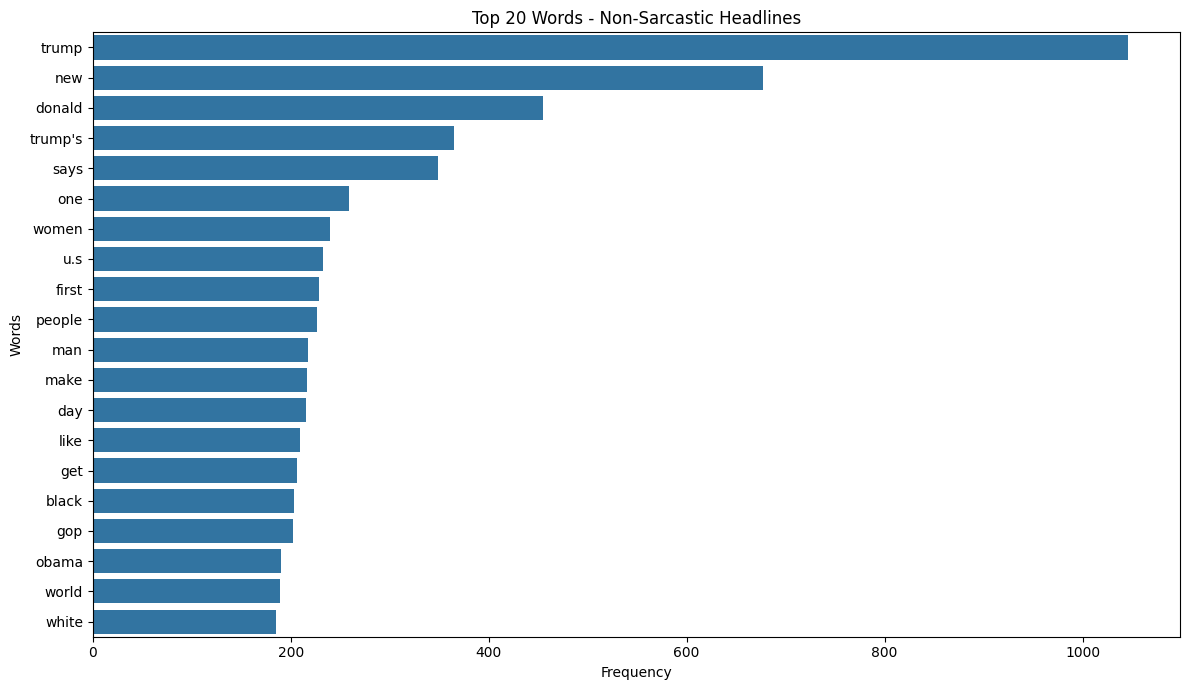

In [27]:
class_0 = df[df['is_sarcastic'] == 0]

class_0_words = get_word_frequency(class_0['headline'], stop_words)

top_20_class_0 = class_0_words.most_common(20)

words, counts = zip(*top_20_class_0)

plt.figure(figsize=(12, 7))
sns.barplot(x=list(counts), y=list(words))

plt.title('Top 20 Words - Non-Sarcastic Headlines')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.show()

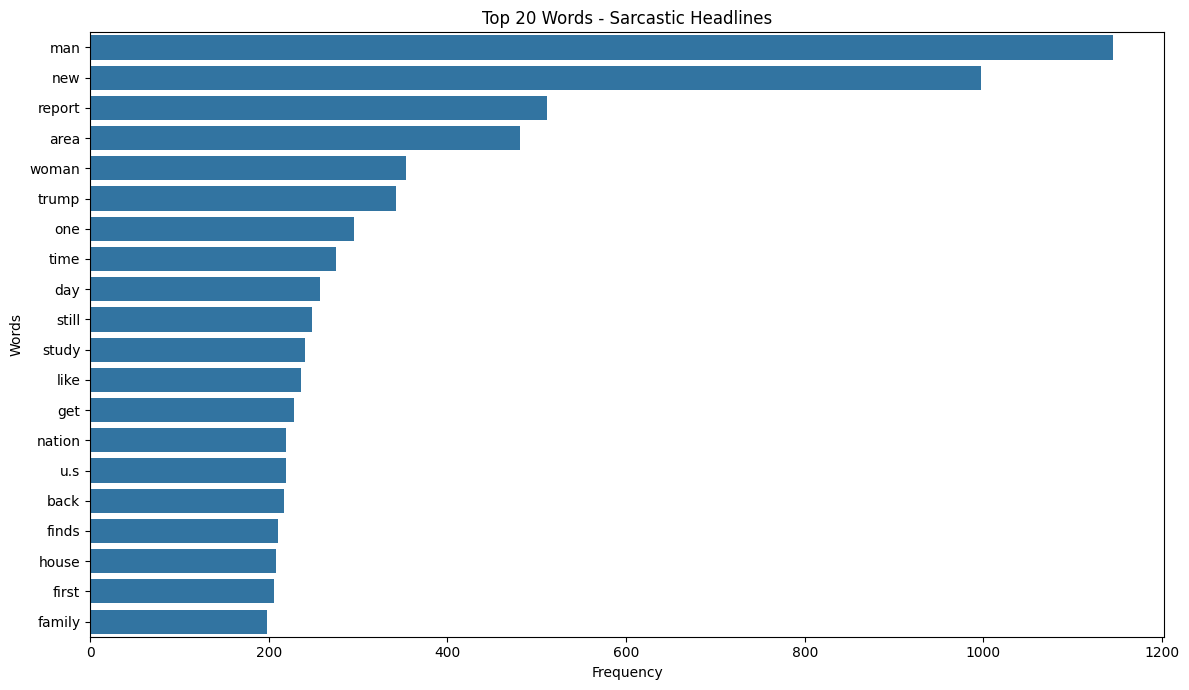

In [28]:
class_1 = df[df['is_sarcastic'] == 1]

class_1_words = get_word_frequency(class_1['headline'], stop_words)

top_20_class_1 = class_1_words.most_common(20)

words, counts = zip(*top_20_class_1)

plt.figure(figsize=(12, 7))
sns.barplot(x=list(counts), y=list(words))

plt.title('Top 20 Words - Sarcastic Headlines')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.show()

#Text cleaning

In [42]:
df_cleanedV= df.copy()
df_cleanedV.head()

,is_sarcastic,headline,article_link,word_count
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...,8
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...,13
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...,7
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...,8
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...,9


In [44]:
import re
#lowercasing
df_cleanedV['cleaned_headline'] = df_cleanedV['headline'].str.lower()
#remove urls & html tags
df_cleanedV['cleaned_headline'] = df_cleanedV['cleaned_headline'].apply(
    lambda text: re.sub(r'http\S+|www\.\S+', ' ', text)
)

df_cleanedV['cleaned_headline'] = df_cleanedV['cleaned_headline'].apply(
    lambda text: re.sub(r'<.*?>', '', text)
)

In [45]:
!pip install contractions
import contractions
df_cleanedV['cleaned_headline'] = df_cleanedV['cleaned_headline'].apply(
    contractions.fix
)
df_cleanedV[['headline', 'cleaned_headline']].sample(
    15, random_state=42
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [contractions]


,headline,cleaned_headline
24106,marco rubio nabs his first 2016 win in minneso...,marco rubio nabs his first 2016 win in minneso...
6020,oops: hot mic broadcasts al roker going to the...,oops: hot mic broadcasts al roker going to the...
20292,white house pretty sure uzbekistan diplomat st...,white house pretty sure uzbekistan diplomat st...
1433,sean hannity informs building tenants about de...,sean hannity informs building tenants about de...
27087,switching to renewables will save millions of ...,switching to renewables will save millions of ...
8393,ellie goulding and james corden perform 'love ...,ellie goulding and james corden perform 'love ...
15090,justice department blindsided banking agency o...,justice department blindsided banking agency o...
8674,everything you need to know before watching th...,everything you need to know before watching th...
4178,excitement shifts to concern after coworker br...,excitement shifts to concern after coworker br...
12539,"softball camp hits home run, pairs amputee mil...","softball camp hits home run, pairs amputee mil..."


In [46]:
#remove Punctuation
df_cleanedV['cleaned_headline'] = df_cleanedV['cleaned_headline'].apply(
    lambda text: re.sub(r'[^\w\s]', ' ', text)
)
#Removing Extra Spaces
df_cleanedV['cleaned_headline'] = df_cleanedV['cleaned_headline'].apply(
    lambda text: re.sub(r'\s+', ' ', text).strip()
)

In [47]:
df_cleanedV[['headline', 'cleaned_headline']].sample(10, random_state=42)

,headline,cleaned_headline
24106,marco rubio nabs his first 2016 win in minneso...,marco rubio nabs his first 2016 win in minneso...
6020,oops: hot mic broadcasts al roker going to the...,oops hot mic broadcasts al roker going to the ...
20292,white house pretty sure uzbekistan diplomat st...,white house pretty sure uzbekistan diplomat st...
1433,sean hannity informs building tenants about de...,sean hannity informs building tenants about de...
27087,switching to renewables will save millions of ...,switching to renewables will save millions of ...
8393,ellie goulding and james corden perform 'love ...,ellie goulding and james corden perform love m...
15090,justice department blindsided banking agency o...,justice department blindsided banking agency o...
8674,everything you need to know before watching th...,everything you need to know before watching th...
4178,excitement shifts to concern after coworker br...,excitement shifts to concern after coworker br...
12539,"softball camp hits home run, pairs amputee mil...",softball camp hits home run pairs amputee mili...


In [48]:
#removing stopwords
important_words = {'not', 'no', 'nor', 'never'}

stop_words = stop_words - important_words

In [49]:
print("Total stopwords:", len(stop_words))
print("Negation words:", important_words)
print("Are negation words in stopwords?", important_words.intersection(stop_words))

Total stopwords: 195
Negation words: {'no', 'nor', 'not', 'never'}
Are negation words in stopwords? set()


In [50]:
def remove_stopwords(text):
    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(filtered_words)

In [52]:
df_cleanedV['cleaned_headline'] = df_cleanedV['cleaned_headline'].apply(
    remove_stopwords
)
df_cleanedV[['headline', 'cleaned_headline']].sample(
    15, random_state=42
)

,headline,cleaned_headline
24106,marco rubio nabs his first 2016 win in minneso...,marco rubio nabs first 2016 win minnesota gop ...
6020,oops: hot mic broadcasts al roker going to the...,oops hot mic broadcasts al roker going bathroom
20292,white house pretty sure uzbekistan diplomat st...,white house pretty sure uzbekistan diplomat st...
1433,sean hannity informs building tenants about de...,sean hannity informs building tenants deep sta...
27087,switching to renewables will save millions of ...,switching renewables save millions american lives
8393,ellie goulding and james corden perform 'love ...,ellie goulding james corden perform love like ...
15090,justice department blindsided banking agency o...,justice department blindsided banking agency m...
8674,everything you need to know before watching th...,everything need know watching stranger things ...
4178,excitement shifts to concern after coworker br...,excitement shifts concern coworker brings bake...
12539,"softball camp hits home run, pairs amputee mil...",softball camp hits home run pairs amputee mili...


In [54]:
df_cleanedV.to_csv('sarcasm_cleaned.csv', index=False)

In [58]:
df_cleanedV2= df_cleanedV.drop(
    columns=['article_link', 'word_count']
)

In [61]:
df_cleanedV2.to_csv('sarcasm_cleanedV2.csv', index=False)

In [57]:
from sklearn.model_selection import train_test_split
X=df_cleanedV['cleaned_headline']
y=df_cleanedV['is_sarcastic']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>